# Previsión de demanda: ganarle a «lo mismo que la semana pasada»

**Avanzado · Jornada 2 · Bloque 2.2 · diapositivas ingenuo, exogenas, origen-movil, cv-aleatoria, metricas, p90, ejercicio-prevision y resultado-prevision**

¿Cuántos viajes saldrán de una estación de BiciCiudad la semana que viene, y cuántos como mucho? Comparamos el ingenuo estacional, ETS y un boosting con el tiempo y el calendario, examinados con origen móvil, y sacamos la banda P90.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## 1. La pregunta

Quien reparte bicis entre estaciones necesita saber, cada domingo, cuántos viajes saldrán de cada estación
en los próximos siete días. Y no solo la media: también cuántos **como mucho** en un día malo.

El rival que hay que batir es el más tonto posible, el **ingenuo estacional**: el martes que viene saldrán
los mismos viajes que el martes pasado. Si un modelo no le gana, no merece la pena mantenerlo.

> **Mensaje clave del bloque:** un modelo que no supera al ingenuo es un coste, no un activo.

In [2]:
# Tres ayudas de formato en español.
import warnings

warnings.filterwarnings("ignore")  # avisos de convergencia y de versiones: no cambian los resultados


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import acf
from threadpoolctl import threadpool_limits

_ = threadpool_limits(2)   # dos hilos: el boosting va más deprisa que peleando por todos los núcleos
USO = DATOS / "uso_meteo"

## 2. Cargar y mirar los datos

Tres ficheros de `uso_meteo/`: los viajes de cada estación y día, el calendario (festivos, vacaciones,
grandes eventos, olas de calor) y la meteorología hora a hora. Todo sintético.

In [4]:
viajes = pd.read_csv(USO / "viajes_estacion_dia.csv", parse_dates=["fecha"])
calendario = pd.read_csv(USO / "calendario.csv", parse_dates=["fecha"])
meteo = pd.read_csv(USO / "meteo_hora.csv")

print(f"{n(len(viajes))} filas: {viajes['estacion_id'].nunique()} estaciones × {viajes['fecha'].nunique()} días, "
      f"del {fecha(viajes['fecha'].min())} al {fecha(viajes['fecha'].max())}")
viajes.head()

43.840 filas: 40 estaciones × 1096 días, del 1-10-2023 al 30-9-2026


,fecha,estacion_id,viajes
0,2023-10-01,E-01,434
1,2023-10-01,E-02,905
2,2023-10-01,E-03,925
3,2023-10-01,E-04,361
4,2023-10-01,E-05,417


In [5]:
# La meteorología viene por horas y en UTC: la pasamos a hora de Madrid y la resumimos por día
meteo["fecha"] = pd.to_datetime(bici.hora_local(meteo["ts_utc"]).dt.date)
tiempo_dia = meteo.groupby("fecha").agg(tmax=("temperatura_c", "max"),
                                        lluvia=("lluvia_mm", "sum")).reset_index()
calendario.head(3)

,fecha,dia_semana,festivo_ciudad,festivo_nombre,laborable,vacaciones_escolares,gran_evento,ola_calor,tormenta,tarifa,horas_del_dia
0,2023-10-01,domingo,False,NaN,False,False,NaN,False,False,anterior,24
1,2023-10-02,lunes,False,NaN,True,False,NaN,False,False,anterior,24
2,2023-10-03,martes,False,NaN,True,False,NaN,False,False,anterior,24


Montamos, para una estación, una tabla con un día por fila y todo lo que un modelo puede saber de ese día
con siete días de antelación: el calendario, el tiempo (aquí el que hizo; en producción sería el previsto)
y los viajes de hace 7 y 14 días. Los de ayer **no**: a siete días vista no los tendríamos.

In [6]:
VARIABLES = ["dia_sem", "mes", "dias_desde_inicio", "festivo_ciudad", "laborable", "vacaciones_escolares",
             "gran_evento_hoy", "ola_calor", "tmax", "lluvia", "viajes_hace_7", "viajes_hace_14"]


def preparar(estacion):
    """Viajes diarios de una estación con su calendario, su tiempo y los viajes de hace 7 y 14 días."""
    s = (viajes[viajes["estacion_id"] == estacion][["fecha", "viajes"]]
         .merge(calendario, on="fecha").merge(tiempo_dia, on="fecha")
         .sort_values("fecha").reset_index(drop=True))
    s["dia_sem"] = s["fecha"].dt.dayofweek                             # 0 = lunes
    s["mes"] = s["fecha"].dt.month
    s["dias_desde_inicio"] = (s["fecha"] - s["fecha"].min()).dt.days   # para que vea la tendencia
    s["gran_evento_hoy"] = s["gran_evento"].notna().astype(int)
    for c in ("festivo_ciudad", "laborable", "vacaciones_escolares", "ola_calor"):
        s[c] = s[c].astype(int)
    s["viajes_hace_7"] = s["viajes"].shift(7)
    s["viajes_hace_14"] = s["viajes"].shift(14)
    return s.dropna(subset=["viajes_hace_14"]).reset_index(drop=True)


s = preparar("E-02")   # Intermodal 2, una de las estaciones grandes
s[["fecha", "viajes"] + VARIABLES].tail()

,fecha,viajes,dia_sem,mes,dias_desde_inicio,festivo_ciudad,laborable,vacaciones_escolares,gran_evento_hoy,ola_calor,tmax,lluvia,viajes_hace_7,viajes_hace_14
1077,2026-09-26,1186,5,9,1091,0,0,0,0,0,24.1,0.0,1215.0,1292.0
1078,2026-09-27,1085,6,9,1092,0,0,0,0,0,23.8,10.4,1065.0,1096.0
1079,2026-09-28,1691,0,9,1093,0,1,0,0,0,23.1,0.0,1520.0,1684.0
1080,2026-09-29,1655,1,9,1094,0,1,0,0,0,21.4,0.0,1430.0,1098.0
1081,2026-09-30,1595,2,9,1095,0,1,0,0,0,18.6,0.0,1543.0,1689.0


## 3. El rival: «lo mismo que la semana pasada»

Ocho semanas de invierno en E-02. El ingenuo no tiene nada que ajustar: copia el mismo día de la semana anterior.

In [7]:
ventana = s[(s["fecha"] >= "2026-01-12") & (s["fecha"] <= "2026-03-08")]
error = (ventana["viajes"] - ventana["viajes_hace_7"]).abs()
peor = ventana.loc[error.idxmax()]

print(f"E-02, del 12-1 al 8-3-2026: media de {n(ventana['viajes'].mean())} viajes al día")
print(f"Error medio (MAE) del ingenuo: {n(error.mean())} viajes al día, un {pct(error.mean() / ventana['viajes'].mean(), 0)}")
print(f"Peor día: {fecha(peor['fecha'])}, falla en {n(error.max())} viajes "
      f"(copia los {n(peor['viajes_hace_7'])} de una semana antes y hubo {n(peor['viajes'])})")

E-02, del 12-1 al 8-3-2026: media de 946 viajes al día
Error medio (MAE) del ingenuo: 99 viajes al día, un 11 %
Peor día: 16-2-2026, falla en 446 viajes (copia los 711 de una semana antes y hubo 1.157)


¿Por qué acierta tanto? Porque la serie se parece mucho a sí misma hace una semana. Lo vimos en la Jornada 1
con la autocorrelación: en los viajes horarios del sistema, a 168 horas (una semana) vale 0,81. Aquí está
calculada también para cada una de las 40 estaciones, en las mismas ocho semanas de otoño de 2025.

In [8]:
horas = pd.read_parquet(USO / "viajes_estacion_hora.parquet")
horas["local"] = bici.hora_local(horas["ts_utc"])
otono = horas[(horas["local"] >= pd.Timestamp("2025-10-06", tz=bici.ZONA))
              & (horas["local"] < pd.Timestamp("2025-12-01", tz=bici.ZONA))]
por_estacion = otono.pivot_table(index="ts_utc", columns="estacion_id", values="viajes", observed=True)

acf_168 = pd.Series({e: acf(por_estacion[e], nlags=168)[168] for e in por_estacion.columns})
acf_sistema = acf(por_estacion.sum(axis=1), nlags=168)[168]
print(f"Sistema completo: {n(acf_sistema, 2)}")
print(f"40 estaciones: de {n(acf_168.min(), 2)} a {n(acf_168.max(), 2)} (mediana {n(acf_168.median(), 2)})")

Sistema completo: 0,81
40 estaciones: de 0,57 a 0,79 (mediana 0,75)


## 4. El calor sube los viajes, hasta que se pasa

El ingenuo no sabe qué tiempo va a hacer. Veamos cuánto importa: viajes diarios de todo el sistema según la
temperatura máxima, en los dos últimos años, con los días de ola de calor aparte.

In [9]:
sistema = viajes.groupby("fecha")["viajes"].sum().rename("viajes").reset_index()
sistema = sistema.merge(tiempo_dia, on="fecha").merge(calendario[["fecha", "ola_calor"]], on="fecha")
sistema = sistema[(sistema["fecha"] >= "2024-10-01") & (sistema["fecha"] <= "2026-09-30")]

ola = sistema[sistema["ola_calor"]]
resto = sistema[~sistema["ola_calor"]]
tramos = pd.cut(resto["tmax"], np.arange(0, 46, 3))   # tramos de 3 grados
perfil = resto.groupby(tramos, observed=True)["viajes"].agg(["median", "size"])
perfil = perfil[perfil["size"] >= 10]                  # solo tramos con al menos 10 días

print(perfil.rename(columns={"median": "mediana de viajes", "size": "días"}).to_string())
print(f"\nOlas de calor: {len(ola)} días, máximas de {n(ola['tmax'].min(), 1)} a {n(ola['tmax'].max(), 1)} °C, "
      f"mediana de {n(ola['viajes'].median())} viajes")

          mediana de viajes  días
tmax                             
(3, 6]               8594.0    13
(6, 9]               9894.5    62
(9, 12]             10599.0    70
(12, 15]            12006.0    79
(15, 18]            13100.0    87
(18, 21]            14159.0    63
(21, 24]            15532.5    74
(24, 27]            15661.0    58
(27, 30]            15746.0    85
(30, 33]            16233.0    71
(33, 36]            13023.5    46

Olas de calor: 14 días, máximas de 41,0 a 43,0 °C, mediana de 11.488 viajes


La relación tiene forma de joroba: más calor, más viajes, hasta unos 33 °C; con la ola de calor, la mediana
cae a unos 11.500. Una recta no lo captaría; los árboles del boosting sí. Y el ingenuo, si la semana pasada
fue normal, copiará una semana normal.

## 5. La escalera de modelos

1. **Ingenuo estacional:** la columna `viajes_hace_7`. Nada que ajustar.
2. **ETS:** suavizado exponencial con nivel, tendencia amortiguada y ritmo semanal, sobre el último año.
3. **Gradient boosting:** árboles pequeños que se corrigen unos a otros, con las `VARIABLES` de arriba.

In [10]:
MODELOS = ["ingenuo", "ets", "boosting"]


def boosting(**opciones):
    # Los mismos ajustes que el cálculo de las diapositivas
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         random_state=2026, **opciones)


def prever_ets(viajes_pasados, dias):
    modelo = ExponentialSmoothing(viajes_pasados[-365:], trend="add", damped_trend=True,
                                  seasonal="add", seasonal_periods=7)
    return modelo.fit().forecast(dias)


def mae(tabla, modelo):
    """Error absoluto medio en viajes al día."""
    return (tabla[modelo] - tabla["real"]).abs().mean()

## 6. Se entrena con el pasado y se examina con el futuro

**Origen móvil:** cada domingo se entrena con todo lo anterior y se prevén los siete días siguientes; el
corte avanza una semana cada vez. Es lo que le pasará al modelo en la vida real. En scikit-learn lo hace
`TimeSeriesSplit`; mirad los primeros cortes:

In [11]:
hasta_junio = s[s["fecha"] <= "2026-06-28"]
cortes = TimeSeriesSplit(n_splits=52, test_size=7)     # 52 semanas de examen, de 7 días cada una
for i, (entreno, prueba) in enumerate(cortes.split(hasta_junio)):
    if i < 3 or i == 51:
        f = hasta_junio["fecha"]
        print(f"Corte {i + 1:2d}: entrena hasta el {fecha(f.iloc[entreno[-1]])}, "
              f"examina del {fecha(f.iloc[prueba[0]])} al {fecha(f.iloc[prueba[-1]])}")

Corte  1: entrena hasta el 29-6-2025, examina del 30-6-2025 al 6-7-2025
Corte  2: entrena hasta el 6-7-2025, examina del 7-7-2025 al 13-7-2025
Corte  3: entrena hasta el 13-7-2025, examina del 14-7-2025 al 20-7-2025
Corte 52: entrena hasta el 21-6-2026, examina del 22-6-2026 al 28-6-2026


Lo mismo, escrito con fechas para poder elegir los domingos de corte. Para cada semana guardamos lo real y lo
que dijo cada modelo.

In [12]:
def origen_movil(s, primer_domingo, ultimo_domingo):
    semanas = []
    for corte in pd.date_range(primer_domingo, ultimo_domingo, freq="7D"):
        pasado = s[s["fecha"] <= corte]
        semana = s[(s["fecha"] > corte) & (s["fecha"] <= corte + pd.Timedelta(days=7))]
        if semana.empty:
            continue
        semanas.append(pd.DataFrame({
            "fecha": semana["fecha"],
            "real": semana["viajes"],
            "ingenuo": semana["viajes_hace_7"],
            "ets": prever_ets(pasado["viajes"].to_numpy(), len(semana)),
            "boosting": boosting().fit(pasado[VARIABLES], pasado["viajes"]).predict(semana[VARIABLES]),
        }))
    return pd.concat(semanas, ignore_index=True)


# Un año de exámenes: de julio de 2025 a junio de 2026 (52 domingos)
e02 = origen_movil(s, "2025-06-29", "2026-06-21")
print("E-02, MAE en viajes al día con origen móvil:")
for m in MODELOS:
    print(f"  {m:9s} {n(mae(e02, m), 1)}")

E-02, MAE en viajes al día con origen móvil:
  ingenuo   153,9
  ets       127,6
  boosting  108,9


## 7. Barajar la serie promete un error que nunca verás

El mismo boosting, examinado de tres maneras:

- **validación cruzada aleatoria** (lo que sale por defecto): barajamos los días hasta junio de 2026 en cinco
  bloques y examinamos cada bloque con un modelo entrenado con los otros cuatro;
- **origen móvil**, como arriba;
- **lo que pasó de verdad** al ponerlo a trabajar de julio a septiembre de 2026.

In [13]:
semilla = 2026   # ← probad otra: la aleatoria sigue saliendo demasiado bonita

historia = s[s["fecha"] <= "2026-06-30"]
errores = []
for entreno, prueba in KFold(5, shuffle=True, random_state=semilla).split(historia):
    modelo = boosting().fit(historia.iloc[entreno][VARIABLES], historia.iloc[entreno]["viajes"])
    prevision = modelo.predict(historia.iloc[prueba][VARIABLES])
    errores.append(np.abs(prevision - historia.iloc[prueba]["viajes"]).mean())

verano = origen_movil(s, "2026-06-28", "2026-09-27")   # lo real: de julio a septiembre de 2026

aleatoria, movil, real = np.mean(errores), mae(e02, "boosting"), mae(verano, "boosting")
print(f"Validación aleatoria: {n(aleatoria, 1)} viajes al día")
print(f"Origen móvil:         {n(movil, 1)}")
print(f"Lo que pasó de verdad: {n(real, 1)}")
print(f"La aleatoria prometió un {pct(1 - aleatoria / real, 0)} menos de error del que hubo.")

Validación aleatoria: 67,4 viajes al día
Origen móvil:         108,9
Lo que pasó de verdad: 144,7
La aleatoria prometió un 53 % menos de error del que hubo.


¿Por qué sale tan bien la aleatoria? Porque el modelo tiene la fecha entre sus variables y, con los días
barajados, ha visto el día de antes y el de después de cada día del examen. La demanda tiene rachas. En la
vida real los vecinos del futuro no existen. Y fijaos en que tampoco el origen móvil acierta del todo: el
verano, con la ola de calor, fue más difícil que el año con el que se examinó.

## 8. Métricas: el MAPE se dispara cuando los viajes rozan el cero

- **MAE:** en viajes al día. Lo entiende cualquiera.
- **MAPE:** divide cada error por el valor real. Con valores pequeños se dispara, y con ceros no se puede calcular.
- **Pérdida pinball:** para juzgar cuantiles como el P90.

El MAPE del ingenuo en una estación pequeña, E-39, hora a hora (la misma hora de la semana anterior):

In [14]:
e39 = horas[horas["estacion_id"] == "E-39"].sort_values("ts_utc").copy()
e39["ingenuo"] = e39["viajes"].shift(168)          # la misma hora de la semana anterior
anio = e39[(e39["local"] >= pd.Timestamp("2025-07-01", tz=bici.ZONA))
           & (e39["local"] < pd.Timestamp("2026-07-01", tz=bici.ZONA))]

error_h = (anio["viajes"] - anio["ingenuo"]).abs()
con_viajes = anio["viajes"] > 0
print(f"Horas con cero viajes: {n(( ~con_viajes).sum())} de {n(len(anio))} (ahí el MAPE no se puede calcular)")
print(f"MAE horario: {n(error_h.mean(), 1)} viajes; MAE / media: {pct(error_h.mean() / anio['viajes'].mean(), 0)}")
print(f"MAPE quitando los ceros: {pct((error_h[con_viajes] / anio.loc[con_viajes, 'viajes']).mean(), 0)}")
for nombre, horas_sel in (("con 1 o 2 viajes", anio["viajes"].between(1, 2)), ("con 10 o más", anio["viajes"] >= 10)):
    mape_sel = (error_h[horas_sel] / anio.loc[horas_sel, "viajes"]).mean()
    print(f"  MAPE en las horas {nombre}: {pct(mape_sel, 0)} ({n(horas_sel.sum())} horas)")

Horas con cero viajes: 1.204 de 8.760 (ahí el MAPE no se puede calcular)
MAE horario: 3,1 viajes; MAE / media: 44 %
MAPE quitando los ceros: 66 %
  MAPE en las horas con 1 o 2 viajes: 121 % (1.853 horas)
  MAPE en las horas con 10 o más: 34 % (2.457 horas)


Las horas con uno o dos viajes, las que menos importan, son las que inflan el MAPE, y las horas a cero ni
siquiera se pueden calcular. Si necesitáis un porcentaje, dividid el MAE por la media.

La **pérdida pinball** del cuantil 0,9 castiga quedarse corto nueve veces más que pasarse, que es justo lo
que pide un P90:

In [15]:
def pinball(real, prevision, cuantil):
    error = np.asarray(real) - np.asarray(prevision)
    return np.mean(np.maximum(cuantil * error, (cuantil - 1) * error))


print("Corto por 100 viajes:", n(pinball([1100], [1000], 0.9)))   # 0,9 × 100 = 90
print("Largo por 100 viajes:", n(pinball([900], [1000], 0.9)))    # 0,1 × 100 = 10

Corto por 100 viajes: 90
Largo por 100 viajes: 10


## 9. Para dimensionar anclajes hace falta el P90, no la media

La forma más sencilla de hacer la banda: guardar cuánto se equivocó el boosting con origen móvil (el cociente
real / previsto) y usar sus percentiles 10 y 90. Después vemos si la banda aguantó el verano.

In [16]:
cociente = e02["real"] / e02["boosting"]
c10, c90 = cociente.quantile(0.1), cociente.quantile(0.9)
verano["p10"] = verano["boosting"] * c10
verano["p90"] = verano["boosting"] * c90

dentro = verano["real"].between(verano["p10"], verano["p90"]).mean()
encima = (verano["real"] > verano["p90"]).mean()
print(f"P10 = previsión × {n(c10, 3)}; P90 = previsión × {n(c90, 3)}")
print(f"De julio a septiembre de 2026, la banda P10-P90 cubre el {pct(dentro, 0)} de los días (debería, el 80 %)")
print(f"y el {pct(encima, 0)} supera el P90 (debería, el 10 %)")

semana = verano[(verano["fecha"] >= "2026-09-14") & (verano["fecha"] <= "2026-09-20")]
pico = semana.loc[semana["boosting"].idxmax()]
print(f"\nSemana del 14 al 20-9, prevista el domingo 13: el día de más demanda es el {fecha(pico['fecha'])}, "
      f"con {n(pico['boosting'])} viajes previstos y un P90 de {n(pico['p90'])}")
print(f"Días reales dentro de la banda esa semana: {semana['real'].between(semana['p10'], semana['p90']).sum()} de 7")

P10 = previsión × 0,852; P90 = previsión × 1,174
De julio a septiembre de 2026, la banda P10-P90 cubre el 67 % de los días (debería, el 80 %)
y el 16 % supera el P90 (debería, el 10 %)

Semana del 14 al 20-9, prevista el domingo 13: el día de más demanda es el 14-9-2026, con 1.709 viajes previstos y un P90 de 2.007
Días reales dentro de la banda esa semana: 7 de 7


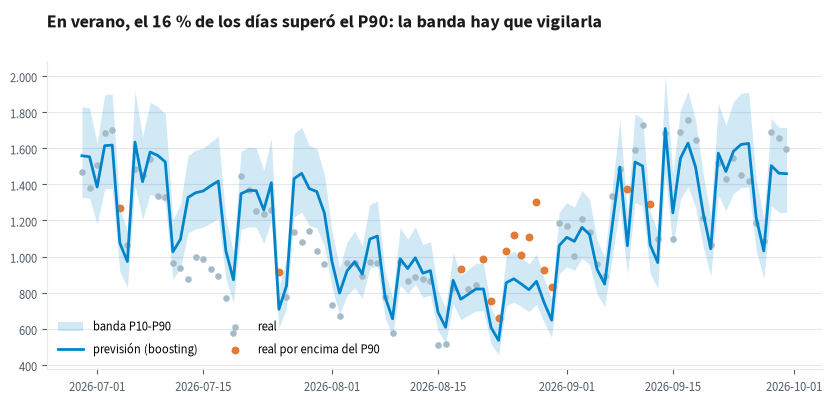

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(verano["fecha"], verano["p10"], verano["p90"], color=estilo.AZUL, alpha=0.18,
                linewidth=0, label="banda P10-P90")
ax.plot(verano["fecha"], verano["boosting"], color=estilo.AZUL, label="previsión (boosting)")
fuera = verano["real"] > verano["p90"]
ax.scatter(verano.loc[~fuera, "fecha"], verano.loc[~fuera, "real"], s=14, color=estilo.GRIS, label="real")
ax.scatter(verano.loc[fuera, "fecha"], verano.loc[fuera, "real"], s=22, color=estilo.NARANJA,
           label="real por encima del P90")
ax.set_title(f"En verano, el {pct(encima, 0)} de los días superó el P90: la banda hay que vigilarla")
estilo.formato_eje(ax)
ax.legend(loc="lower left", ncol=2)
plt.show()

El otro camino es pedirle el cuantil al propio boosting (`loss="quantile"`), que minimiza la pinball.
Lo comparamos con la banda del cociente en el mismo verano. Cuanto más baja la pinball, mejor.

In [18]:
p90_cuantil = []
for corte in pd.date_range("2026-06-28", "2026-09-27", freq="7D"):
    pasado = s[s["fecha"] <= corte]
    semana_c = s[(s["fecha"] > corte) & (s["fecha"] <= corte + pd.Timedelta(days=7))]
    modelo = boosting(loss="quantile", quantile=0.9).fit(pasado[VARIABLES], pasado["viajes"])
    p90_cuantil.extend(modelo.predict(semana_c[VARIABLES]))
verano["p90_cuantil"] = p90_cuantil

for col, nombre in (("p90", "cociente de errores"), ("p90_cuantil", "boosting con cuantil")):
    print(f"{nombre:21s} pinball {n(pinball(verano['real'], verano[col], 0.9), 1)}; "
          f"días por encima del P90: {pct((verano['real'] > verano[col]).mean(), 0)}")

cociente de errores   pinball 33,9; días por encima del P90: 16 %
boosting con cuantil  pinball 41,0; días por encima del P90: 28 %


Aquí gana la banda sencilla: menos pinball y menos días por encima del P90. Pedirle el cuantil al modelo no
es magia; también hay que examinarlo con el futuro.

## 10. Ejercicio (equipos, 30 min): ingenuo, ETS o boosting, ¿quién gana en tres estaciones?

- **E-02** · Intermodal 2, grande: unos 1.100 viajes al día.
- **E-15** · Paseo del Río 2, mediana: unos 335.
- **E-39** · Jardín Botánico 2, pequeña: unos 170.

Origen móvil semanal de julio de 2025 a junio de 2026, horizonte de 7 días y MAE en viajes al día. Rellenad la
tabla y contestad: ¿quién gana en cada estación?, ¿cuánto mejora al ingenuo?, ¿lo pondríais en producción?
Cada estación tarda unos segundos.

In [19]:
estaciones = ["E-02"]   # ← COMPLETAD: añadid "E-15" y "E-39"

resultados = {"E-02": e02}   # E-02 ya está calculada arriba
for est in estaciones:
    if est not in resultados:
        resultados[est] = origen_movil(preparar(est), "2025-06-29", "2026-06-21")

tabla = pd.DataFrame({est: {m: mae(r, m) for m in MODELOS} for est, r in resultados.items()}).T
tabla["ganador"] = tabla[MODELOS].idxmin(axis=1)
tabla["mejora_%"] = 0   # COMPLETAD: % de mejora del ganador frente al ingenuo (negativo = menos error)
tabla.round(1)

,ingenuo,ets,boosting,ganador,mejora_%
E-02,153.9,127.6,108.9,boosting,0


In [20]:
# El error en las dos unidades: viajes al día y porcentaje de la media de la estación
for est, r in resultados.items():
    media = r["real"].mean()
    print(f"{est}: media {n(media)} viajes al día; boosting falla {n(mae(r, 'boosting'))} viajes, "
          f"un {pct(mae(r, 'boosting') / media, 0)}")

E-02: media 1.076 viajes al día; boosting falla 109 viajes, un 10 %


Si os sobra tiempo: ¿en qué semanas falla más el ingenuo en E-02? Es donde el calendario y el tiempo aportan.

In [21]:
semanal = e02.assign(semana=e02["fecha"] - pd.to_timedelta(e02["fecha"].dt.dayofweek, unit="D"))
semanal = semanal.merge(calendario[["fecha", "festivo_nombre", "ola_calor"]], on="fecha")
semanal["error_ingenuo"] = (semanal["ingenuo"] - semanal["real"]).abs()
semanal["error_boosting"] = (semanal["boosting"] - semanal["real"]).abs()
por_semana = semanal.groupby("semana").agg(
    ingenuo=("error_ingenuo", "mean"),
    boosting=("error_boosting", "mean"),
    festivos=("festivo_nombre", lambda x: ", ".join(x.dropna())),
    ola_calor=("ola_calor", "any"))
por_semana.sort_values("ingenuo", ascending=False).head(6).round(0)

,ingenuo,boosting,festivos,ola_calor
semana,,,,
2025-07-14,392.0,175.0,,False
2025-07-07,343.0,372.0,,True
2026-06-22,331.0,161.0,Fiesta de la ciudad,False
2026-06-08,308.0,217.0,,False
2025-09-08,283.0,263.0,,False
2026-06-15,273.0,102.0,,False


## Qué os lleváis

- El **ingenuo estacional** va siempre en la primera fila de la tabla: es la vara de medir.
- Examinad con **origen móvil**, nunca barajando: la validación aleatoria prometió la mitad del error real.
- Dad el error en las unidades de quien decide (viajes al día) y, para dimensionar, el **P90**. Y vigilad
  la banda: en verano se superó más de lo que prometía.
- Un modelo que no supera al ingenuo es un coste, no un activo; y uno que lo supera por poco tiene que pagar
  lo que cuesta mantenerlo.